
=== final result ===
True reward probabilities:           [0.2, 0.5, 0.75]
Estimated reward probabilities:    [0.   0.   0.72]
Number of times each arm was selected: [ 1.  1. 98.]
Total rewards Earned:                       71


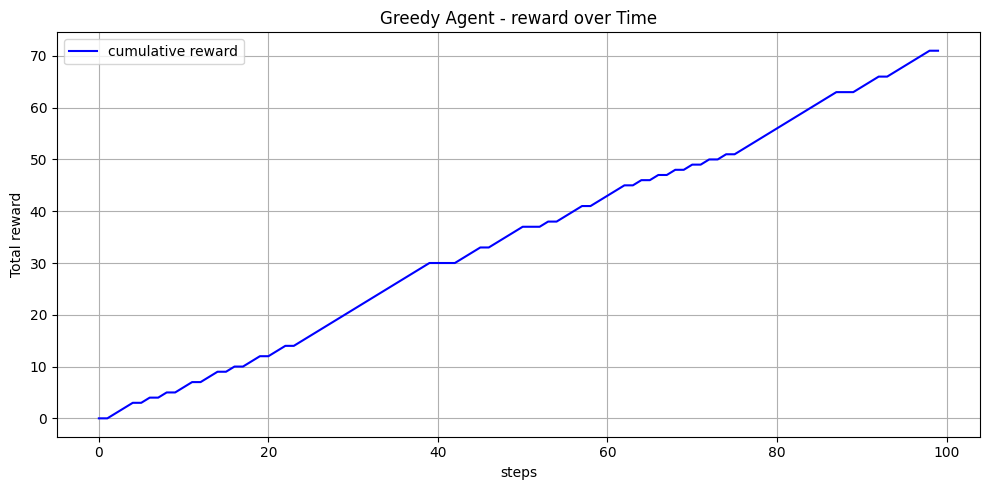

In [1]:
import numpy as np
import matplotlib.pyplot as plt
n_arms = 3
true_rewards = [0.2, 0.5, 0.75]
n_steps = 100
reward_sums = np.zeros(n_arms)
counts = np.zeros(n_arms)
estimated_rewards = np.zeros(n_arms)
reward_history = []
cumulative_reward = []
for arm_idx in range(n_arms):
    reward = int(np.random.rand() < true_rewards[arm_idx])
    reward_sums[arm_idx] += reward
    counts[arm_idx] += 1
    estimated_rewards[arm_idx] = reward_sums[arm_idx] / counts[arm_idx]
    reward_history.append(reward)
    if not cumulative_reward:
        cumulative_reward.append(reward)
    else:
        cumulative_reward.append(cumulative_reward[-1] + reward)
for step in range(n_arms, n_steps):
    chosen_arm = np.argmax(estimated_rewards)
    reward = int(np.random.rand() < true_rewards[chosen_arm])
    reward_sums[chosen_arm] += reward
    counts[chosen_arm] += 1
    estimated_rewards[chosen_arm] = reward_sums[chosen_arm] / counts[chosen_arm]
    reward_history.append(reward)
    cumulative_reward.append(cumulative_reward[-1] + reward)
print("\n=== final result ===")
print("True reward probabilities:          ", true_rewards)
print("Estimated reward probabilities:   ", np.around(estimated_rewards, 2))
print("Number of times each arm was selected:", counts)
print("Total rewards Earned:                      ", int(sum(reward_history)))
plt.figure(figsize=(10, 5))
plt.plot(cumulative_reward, label="cumulative reward", color="blue")
plt.xlabel("steps")
plt.ylabel("Total reward")
plt.title("Greedy Agent - reward over Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
